In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

status = pd.read_parquet("../data/processed/stations_status.parquet")
# stations avec assez de relevés, hors maintenance
status = status[status["enough_snapshots"] & ~status["maintenance"]]


2. Série horaire régulière




In [3]:
hourly = (status.set_index("time")
          .groupby("station_id")["bikes_available_to_rent"]
          .resample("1h").last()                 # dernière valeur connue dans l'heure
          .groupby(level=0).ffill(limit=6)       # on recopie la valeur au plus 6 h
          .rename("bikes").reset_index())

# capacité et fuseau horaire de chaque station
infos = status.drop_duplicates("station_id")[["station_id", "capacity", "timezone"]]
hourly = hourly.merge(infos, on="station_id")
hourly.shape


(17325615, 5)

3. Variables et cible




In [4]:
# heure locale
parts = [g["time"].dt.tz_convert(tz).dt.tz_localize(None) for tz, g in hourly.groupby("timezone")]
hourly["time_local"] = pd.concat(parts).reindex(hourly.index)
hourly["hour"]       = hourly["time_local"].dt.hour
hourly["weekday"]    = hourly["time_local"].dt.day_of_week
hourly["is_weekend"] = (hourly["weekday"] >= 5).astype(int)

g = hourly.groupby("station_id")["bikes"]
hourly["target"] = g.shift(-1)                   # vélos dans 1 h  ← ce qu'on prédit
hourly["lag_1"]  = g.shift(1)                    # il y a 1 h
hourly["lag_24"] = g.shift(24)                   # hier à la même heure
hourly["diff_1"] = hourly["bikes"] - hourly["lag_1"]   # tendance récente

hourly = hourly.dropna()
features = ["bikes", "lag_1", "lag_24", "diff_1", "hour", "weekday", "is_weekend", "capacity"]
hourly.shape


(2833043, 13)

4. Découpage dans le temps




In [5]:
cut = pd.Timestamp("2023-05-01", tz="UTC")
train = hourly[hourly["time"] < cut]
test  = hourly[hourly["time"] >= cut]
print("train :", len(train), "| test :", len(test))

X_train, y_train = train[features], train["target"]
X_test,  y_test  = test[features],  test["target"]


train : 1933366 | test : 899677


5. Référence naïve




In [6]:
def evaluate(name, y_true, y_pred):
    return {"modèle": name,
            "MAE":  mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

results = [evaluate("naïf (même valeur)", y_test, test["bikes"])]


6. Modèles




In [7]:
lr = LinearRegression().fit(X_train, y_train)
results.append(evaluate("régression linéaire", y_test, lr.predict(X_test)))

hgb = HistGradientBoostingRegressor(random_state=42).fit(X_train, y_train)
pred = hgb.predict(X_test)
results.append(evaluate("gradient boosting", y_test, pred))
results.append(evaluate("gradient boosting arrondi", y_test, np.round(pred).clip(0)))  # nb de vélos entier

pd.DataFrame(results).set_index("modèle").round(3)


,MAE,RMSE
modèle,,
naïf (même valeur),0.433,1.047
régression linéaire,0.481,1.038
gradient boosting,0.482,1.025
gradient boosting arrondi,0.435,1.036


7. Analyse des erreurs




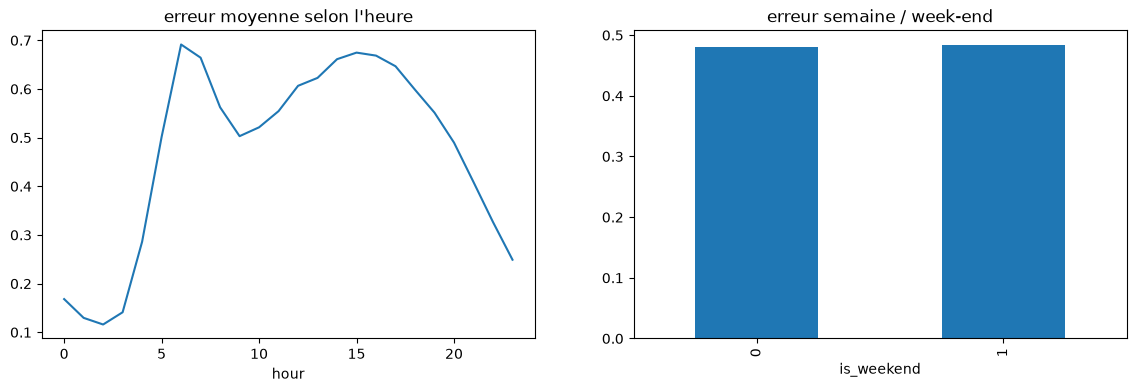

In [8]:
test = test.assign(error=np.abs(y_test - pred))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
test.groupby("hour")["error"].mean().plot(ax=ax[0], title="erreur moyenne selon l'heure")
test.groupby("is_weekend")["error"].mean().plot.bar(ax=ax[1], title="erreur semaine / week-end")
plt.show()


8. Sauvegarde pour l'évaluation finale




In [10]:
from pathlib import Path

MODELS = Path("../models")
MODELS.mkdir(exist_ok=True)

joblib.dump(hgb, MODELS / "hgb_model.joblib")
# le jour J : model = joblib.load(MODELS / "hgb_model.joblib") puis model.predict(X_eval), sans réentraîner


['..\\models\\hgb_model.joblib']